# Independent model audit — Stage 1

This notebook **only reads saved audit tables**. It does not fit models, call predict_proba, regenerate source data, or write figures/reports. Historical saved November–December verification is separate from new January–October development evidence. All periods were previously examined; none is a newly untouched test set.

Read `reports/independent_model_audit.md` for protocol, commands, diagnostics and limits.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'experiments/independent_audit').exists(): ROOT=ROOT.parent
OUT=ROOT/'outputs/experiments/independent_audit/stage1_audit_001'
fold=pd.read_csv(OUT/'fold_metrics.csv')
primary=fold.loc[fold.grid.eq('primary')]
monthly=pd.read_csv(OUT/'fold_monthly_metrics.csv')
print('Run:',OUT.name)
display(pd.DataFrame(json.loads((OUT/'protocol.json').read_text())['versions'].items(),columns=['package','version']))

Matplotlib is building the font cache; this may take a moment.


Run: stage1_audit_001


,package,version
0,numpy,2.5.5
1,scipy,1.18.1
2,pandas,2.3.1
3,scikit-learn,1.7.2
4,matplotlib,3.10.7
5,joblib,1.6.0
6,threadpoolctl,3.8.0
7,nbclient,0.11.0
8,nbformat,5.11.1
9,ipykernel,7.1.0


## Historical verification — saved test probabilities only
Full-year reconstruction is audited by flight_id. These charts load saved verification tables; no new inference is performed.

,model,split,threshold,n,positive_count,negative_count,prevalence,mean_probability,tn,fp,...,precision,recall,f1,tpr,fpr,f1_q20,roc_auc,average_precision,brier,log_loss
0,decision_tree,test,0.175,54145,11815,42330,0.218210,0.264730,27004,15326,...,0.303205,0.564452,0.394499,0.564452,0.362060,0.374716,0.615798,0.278807,0.209080,0.621743
1,decision_tree,validation,0.175,55775,8334,47441,0.149422,0.268646,29876,17565,...,0.221858,0.600912,0.324069,0.600912,0.370249,0.389961,0.630173,0.199055,0.185200,0.558024
2,logistic_regression,test,0.325,54145,11815,42330,0.218210,0.315081,25712,16618,...,0.305268,0.618028,0.408675,0.618028,0.392582,0.387678,0.653322,0.321336,0.177973,0.533539
3,logistic_regression,validation,0.325,55775,8334,47441,0.149422,0.292701,30546,16895,...,0.233022,0.615911,0.338120,0.615911,0.356127,0.405149,0.675439,0.246266,0.148828,0.464342
4,majority_baseline,test,0.500,54145,11815,42330,0.218210,0.000000,42330,0,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.218210,0.218210,7.536719
5,majority_baseline,validation,0.500,55775,8334,47441,0.149422,0.000000,47441,0,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.149422,0.149422,5.160846
6,random_forest,test,0.250,54145,11815,42330,0.218210,0.248664,23714,18616,...,0.295889,0.662124,0.409003,0.662124,0.439783,0.387065,0.645101,0.311816,0.165662,0.510849
7,random_forest,validation,0.250,55775,8334,47441,0.149422,0.249014,26256,21185,...,0.219188,0.713583,0.335363,0.713583,0.446555,0.407785,0.675547,0.247750,0.131853,0.435926


,model,max_abs_probability_difference,mean_abs_probability_difference,input_names,encoded_dimension,iterations
0,majority_baseline,0.000000e+00,0.000000e+00,"['month', 'day_of_week', 'day_of_year', 'is_we...",3388,NaN
1,logistic_regression,0.000000e+00,0.000000e+00,"['month', 'day_of_week', 'day_of_year', 'is_we...",3388,[19]
2,decision_tree,0.000000e+00,0.000000e+00,"['month', 'day_of_week', 'day_of_year', 'is_we...",3388,NaN
3,random_forest,1.110223e-16,3.127136e-18,"['month', 'day_of_week', 'day_of_year', 'is_we...",3388,NaN


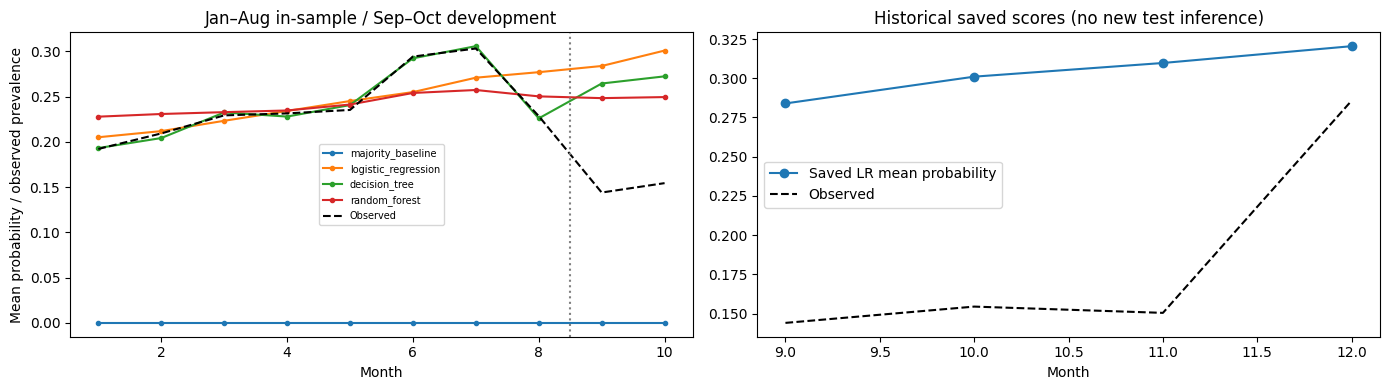

,model,period,n,positive_count,negative_count,prevalence,mean_probability,tn,fp,fn,...,precision,recall,f1,tpr,fpr,f1_q20,roc_auc,average_precision,brier,log_loss
0,majority_baseline,train_optimistic,218601,52765,165836,0.241376,0.000000,165836,0,52765,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.241376,0.241376,8.336826
1,majority_baseline,validation_reused,55775,8334,47441,0.149422,0.000000,47441,0,8334,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.149422,0.149422,5.160846
2,logistic_regression,train_optimistic,218601,52765,165836,0.241376,0.241381,132666,33170,26313,...,0.443662,0.501317,0.470731,0.501317,0.200017,0.435666,0.730846,0.452503,0.160412,0.489763
3,logistic_regression,validation_reused,55775,8334,47441,0.149422,0.292701,30546,16895,3201,...,0.233022,0.615911,0.338120,0.615911,0.356127,0.405149,0.675439,0.246266,0.148828,0.464342
4,decision_tree,train_optimistic,218601,52765,165836,0.241376,0.241376,90175,75661,9983,...,0.361203,0.810803,0.499766,0.810803,0.456240,0.446015,0.763754,0.538036,0.149567,0.463439
5,decision_tree,validation_reused,55775,8334,47441,0.149422,0.268646,29876,17565,3326,...,0.221858,0.600912,0.324069,0.600912,0.370249,0.389961,0.630173,0.199055,0.185200,0.558024
6,random_forest,train_optimistic,218601,52765,165836,0.241376,0.241554,105556,60280,16603,...,0.374961,0.685341,0.484723,0.685341,0.363492,0.436619,0.715886,0.436747,0.171361,0.520921
7,random_forest,validation_reused,55775,8334,47441,0.149422,0.249014,26256,21185,2387,...,0.219188,0.713583,0.335363,0.713583,0.446555,0.407785,0.675547,0.247750,0.131853,0.435926


In [2]:
display(pd.read_csv(OUT/'historical_recomputed.csv'))
display(pd.read_csv(OUT/'historical_pipeline_checks.csv'))
history=pd.read_csv(OUT/'historical_development_monthly.csv')
saved=pd.read_csv(OUT/'historical_saved_monthly.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4))
for name in history.model.unique():
    g=history.loc[history.model.eq(name)]
    axes[0].plot(g.month,g.mean_probability,marker='.',label=name)
obs=history.loc[history.model.eq('logistic_regression')]
axes[0].plot(obs.month,obs.prevalence,'k--',label='Observed')
axes[0].set(title='Jan–Aug in-sample / Sep–Oct development',xlabel='Month',ylabel='Mean probability / observed prevalence')
axes[0].axvline(8.5,color='gray',linestyle=':');axes[0].legend(fontsize=7)
g=saved.loc[saved.model.eq('logistic_regression')]
axes[1].plot(g.month,g.mean_probability,marker='o',label='Saved LR mean probability')
axes[1].plot(g.month,g.prevalence,'k--',label='Observed')
axes[1].set(title='Historical saved scores (no new test inference)',xlabel='Month');axes[1].legend()
plt.tight_layout();plt.show()
display(pd.read_csv(OUT/'historical_train_validation_ranking.csv'))

## Covariates and observational prevalence decomposition
Disjoint calendar ranges alone do not prove harmful concept drift. Stratum rates separate a coarse schedule-mix component from a residual within-stratum change on reported common support; neither identifies causes.

In [3]:
display(pd.read_csv(OUT/'covariate_distances.csv'))
display(pd.Series(json.loads((OUT/'prevalence_decomposition.json').read_text())))
display(pd.read_csv(OUT/'prior_study_recomputed.csv'))

,feature,distance_type,distance,train_min,train_max,validation_min,validation_max
0,month,KS,1.000000,1.0,8.0,9.0,10.0
1,day_of_week,TV,0.029150,NaN,NaN,NaN,NaN
2,day_of_year,KS,1.000000,1.0,243.0,244.0,304.0
3,is_weekend,TV,0.013929,NaN,NaN,NaN,NaN
4,sched_dep_minutes,KS,0.018015,300.0,1439.0,300.0,1439.0
5,sched_arr_minutes,KS,0.018186,1.0,1439.0,1.0,1439.0
6,carrier,TV,0.024582,NaN,NaN,NaN,NaN
7,flight,TV,0.463227,NaN,NaN,NaN,NaN
8,origin,TV,0.030198,NaN,NaN,NaN,NaN
9,dest,TV,0.054563,NaN,NaN,NaN,NaN


strata                                    153.000000
common_strata                             147.000000
train_support_coverage                      0.999973
validation_support_coverage                 0.998870
all_training_prevalence                     0.241376
all_validation_prevalence                   0.149422
common_training_prevalence                  0.241373
expected_validation_mix_training_rates      0.238741
common_observed_validation_prevalence       0.149429
mix_component_common_support               -0.002633
residual_within_strata                     -0.089311
common_total_change                        -0.091944
dtype: float64

,candidate,n,positive_count,negative_count,prevalence,mean_probability,tn,fp,fn,tp,...,precision,recall,f1,tpr,fpr,f1_q20,roc_auc,average_precision,brier,log_loss
0,decision_tree_original,55775,8334,47441,0.149422,0.268646,29876,17565,3326,5008,...,0.221858,0.600912,0.324069,0.600912,0.370249,0.389961,0.630173,0.199055,0.185200,0.558024
1,forest_interactions_d14,55775,8334,47441,0.149422,0.238225,31535,15906,3383,4951,...,0.237378,0.594072,0.339214,0.594072,0.335280,0.404793,0.679429,0.251076,0.128642,0.423589
2,logistic_regression_original,55775,8334,47441,0.149422,0.292701,30546,16895,3201,5133,...,0.233022,0.615911,0.338120,0.615911,0.356127,0.405149,0.675439,0.246266,0.148828,0.464342
3,lr_cyclic_C1,55775,8334,47441,0.149422,0.217284,31710,15731,3343,4991,...,0.240855,0.598872,0.343544,0.598872,0.331591,0.409452,0.683829,0.255234,0.127963,0.413731
4,lr_interactions_C1,55775,8334,47441,0.149422,0.212085,29902,17539,2980,5354,...,0.233871,0.642429,0.342908,0.642429,0.369701,0.411650,0.680481,0.250381,0.127945,0.413427
5,lr_keyed_C1,55775,8334,47441,0.149422,0.286218,28798,18643,2872,5462,...,0.226592,0.655388,0.336755,0.655388,0.392972,0.406155,0.675184,0.243595,0.147321,0.459979
6,random_forest_original,55775,8334,47441,0.149422,0.249014,26256,21185,2387,5947,...,0.219188,0.713583,0.335363,0.713583,0.446555,0.407785,0.675547,0.247750,0.131853,0.435926


## New development evidence: fixed ablations and threshold transfer
A original; B no month/day-of-year; C no flight; D categorical weekday; E B with departure spline; F compact LR; G matched compact native-categorical HGB. Each threshold is fitted only on its designated past month. Fold d uses Jan–Jul fit / August threshold / Sep–Oct assessment. The diagnostic wider grid does not replace the primary grid.

Fold a


,candidate,threshold,n,prevalence,mean_probability,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
1,A,0.250,28233,0.235363,0.268677,0.607481,0.634267,0.336140,0.684876,0.450951,0.688579,0.388419,0.168002,0.509584
3,B,0.200,28233,0.235363,0.208888,0.627316,0.635101,0.345081,0.649812,0.450778,0.687708,0.387062,0.167109,0.509067
5,C,0.225,28233,0.235363,0.271081,0.561612,0.641148,0.323631,0.791422,0.459402,0.700836,0.404151,0.165084,0.503578
7,D,0.225,28233,0.235363,0.268005,0.574009,0.634463,0.324485,0.748683,0.452746,0.689200,0.388155,0.167958,0.509333
9,E,0.200,28233,0.235363,0.209003,0.624269,0.636599,0.344381,0.659895,0.452575,0.689402,0.386903,0.166873,0.508071
11,F,0.175,28233,0.235363,0.211812,0.575886,0.644232,0.329275,0.773363,0.461891,0.700397,0.401113,0.164922,0.502157
13,G,0.200,28233,0.235363,0.212435,0.620550,0.649115,0.348345,0.703085,0.465872,0.705653,0.410629,0.163444,0.498090
14,always_positive,0.500,28233,0.235363,1.000000,0.235363,0.500000,0.235363,1.000000,0.381042,0.500000,0.235363,0.764637,26.410242
15,majority,0.500,28233,0.235363,0.000000,0.764637,0.500000,NaN,0.000000,0.000000,0.500000,0.235363,0.235363,8.129146
16,training_prior,0.500,28233,0.235363,0.210734,0.764637,0.500000,NaN,0.000000,0.000000,0.500000,0.235363,0.180574,0.547450


Fold b


,candidate,threshold,n,prevalence,mean_probability,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
18,A,0.225,27234,0.294338,0.262254,0.605603,0.640488,0.405072,0.725299,0.519827,0.688785,0.449802,0.191464,0.565065
20,B,0.200,27234,0.294338,0.209231,0.635015,0.634787,0.420443,0.634232,0.505669,0.684884,0.443742,0.198727,0.587091
22,C,0.250,27234,0.294338,0.263910,0.633216,0.651218,0.424781,0.694985,0.527282,0.707317,0.466178,0.187581,0.553921
24,D,0.225,27234,0.294338,0.261840,0.606668,0.640806,0.405734,0.723802,0.519986,0.689188,0.450828,0.191380,0.564839
26,E,0.200,27234,0.294338,0.209136,0.631967,0.634881,0.418408,0.641966,0.506621,0.685953,0.442064,0.198615,0.586284
28,F,0.225,27234,0.294338,0.210377,0.662187,0.638696,0.443662,0.581587,0.503347,0.703182,0.460994,0.195618,0.574708
30,G,0.225,27234,0.294338,0.211331,0.660388,0.645675,0.444011,0.609905,0.513901,0.706147,0.466282,0.194210,0.571492
31,always_positive,0.500,27234,0.294338,1.000000,0.294338,0.500000,0.294338,1.000000,0.454809,0.500000,0.294338,0.705662,24.373268
32,majority,0.500,27234,0.294338,0.000000,0.705662,0.500000,NaN,0.000000,0.000000,0.500000,0.294338,0.294338,10.166073
33,training_prior,0.500,27234,0.294338,0.216175,0.705662,0.500000,NaN,0.000000,0.000000,0.500000,0.294338,0.213813,0.622706


Fold c


,candidate,threshold,n,prevalence,mean_probability,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
35,A,0.200,57326,0.265691,0.264408,0.547064,0.621052,0.344263,0.778938,0.477492,0.669346,0.393049,0.184263,0.549127
37,B,0.150,57326,0.265691,0.215917,0.539999,0.623993,0.343584,0.803230,0.481294,0.675309,0.400938,0.184765,0.553233
39,C,0.200,57326,0.265691,0.269763,0.539773,0.630543,0.346222,0.824240,0.487619,0.686309,0.406379,0.180255,0.538434
41,D,0.175,57326,0.265691,0.264004,0.510135,0.611766,0.331321,0.828639,0.473370,0.668138,0.392101,0.184551,0.549866
43,E,0.150,57326,0.265691,0.215101,0.539145,0.624857,0.343717,0.807760,0.482234,0.675989,0.399122,0.184639,0.552601
45,F,0.175,57326,0.265691,0.217679,0.578394,0.641463,0.362822,0.776049,0.494468,0.692442,0.415535,0.181488,0.542129
47,G,0.175,57326,0.265691,0.216848,0.581917,0.641851,0.364280,0.769746,0.494527,0.696508,0.422682,0.180523,0.539732
48,always_positive,0.500,57326,0.265691,1.000000,0.265691,0.500000,0.265691,1.000000,0.419835,0.500000,0.265691,0.734309,25.362723
49,majority,0.500,57326,0.265691,0.000000,0.734309,0.500000,NaN,0.000000,0.000000,0.500000,0.265691,0.265691,9.176641
50,training_prior,0.500,57326,0.265691,0.220216,0.734309,0.500000,NaN,0.000000,0.000000,0.500000,0.265691,0.197167,0.584680


Fold d


,candidate,threshold,n,prevalence,mean_probability,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier,log_loss
52,A,0.300,55775,0.149422,0.354884,0.517149,0.622543,0.204613,0.772858,0.323563,0.670348,0.242072,0.175112,0.525196
54,B,0.225,55775,0.149422,0.257174,0.561488,0.627440,0.213606,0.721502,0.329624,0.670067,0.240174,0.139916,0.442411
56,C,0.325,55775,0.149422,0.358538,0.540708,0.630062,0.211074,0.757499,0.330152,0.676435,0.247467,0.171859,0.520466
58,D,0.300,55775,0.149422,0.355189,0.519659,0.626393,0.206426,0.778618,0.326335,0.675433,0.248610,0.174411,0.523623
60,E,0.225,55775,0.149422,0.257376,0.555715,0.627657,0.212663,0.730262,0.329400,0.671496,0.241898,0.139520,0.441396
62,F,0.225,55775,0.149422,0.243331,0.579901,0.637869,0.221529,0.720542,0.338873,0.684959,0.256398,0.131590,0.424707
64,G,0.250,55775,0.149422,0.244553,0.609269,0.640048,0.229293,0.683945,0.343446,0.691480,0.269726,0.131128,0.422513
65,always_positive,0.500,55775,0.149422,1.000000,0.149422,0.500000,0.149422,1.000000,0.259995,0.500000,0.149422,0.850578,29.378611
66,majority,0.500,55775,0.149422,0.000000,0.850578,0.500000,NaN,0.000000,0.000000,0.500000,0.149422,0.149422,5.160846
67,training_prior,0.500,55775,0.149422,0.243323,0.850578,0.500000,NaN,0.000000,0.000000,0.500000,0.149422,0.135912,0.448345


,candidate,f1,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,brier,log_loss,f1_q20
0,A,0.482757,0.682237,0.410423,0.586716,0.631936,0.361825,0.729704,0.181243,0.541259,0.406595
1,B,0.479247,0.682634,0.410580,0.600777,0.631294,0.369703,0.695758,0.183534,0.549797,0.406509
2,C,0.491434,0.698154,0.425569,0.578200,0.640970,0.364878,0.770216,0.177640,0.531978,0.414515
3,D,0.482034,0.682175,0.410361,0.563604,0.629012,0.353847,0.767042,0.181296,0.541346,0.404257
4,E,0.480477,0.683781,0.409363,0.598460,0.632112,0.368835,0.703207,0.183375,0.548986,0.407187
5,F,0.486569,0.698673,0.425880,0.605489,0.641464,0.378586,0.710333,0.180676,0.539665,0.415430
6,G,0.491434,0.702769,0.433198,0.620952,0.645547,0.385545,0.694245,0.179392,0.536438,0.420228
7,always_positive,0.418562,0.500000,0.265131,0.265131,0.500000,0.265131,1.000000,0.734869,25.382078,0.333333
8,majority,0.000000,0.500000,0.265131,0.734869,0.500000,NaN,0.000000,0.265131,9.157286,0.000000
9,training_prior,0.000000,0.500000,0.265131,0.734869,0.500000,NaN,0.000000,0.197185,0.584945,0.000000


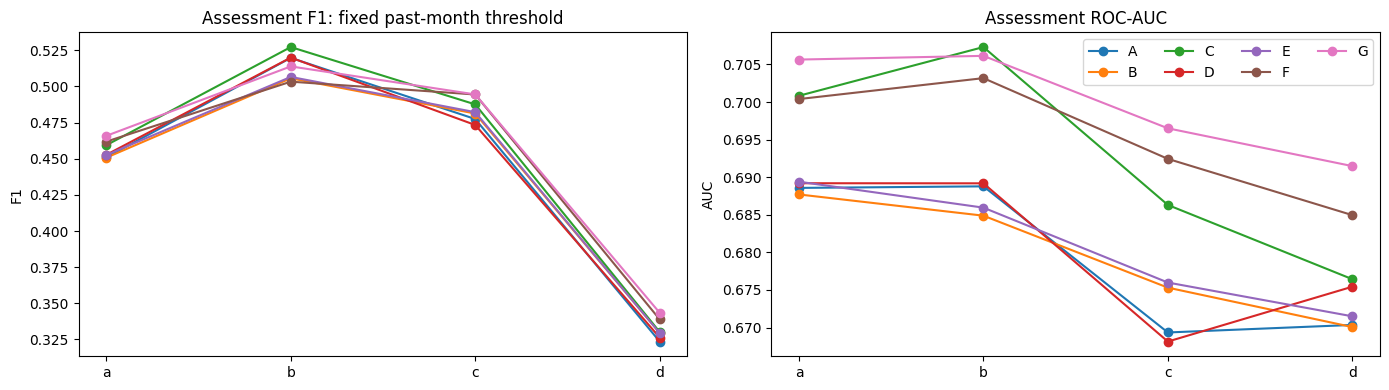

In [4]:
for label,g in primary.groupby('fold'):
    print('Fold',label)
    display(g[['candidate','threshold','n','prevalence','mean_probability','accuracy','balanced_accuracy','precision','recall','f1','roc_auc','average_precision','brier','log_loss']])
display(pd.read_csv(OUT/'equal_weight_abc.csv'))
fig,axes=plt.subplots(1,2,figsize=(14,4))
for name in 'ABCDEFG':
    g=primary.loc[primary.candidate.eq(name)]
    axes[0].plot(g.fold,g.f1,marker='o',label=name)
    axes[1].plot(g.fold,g.roc_auc,marker='o',label=name)
axes[0].set(title='Assessment F1: fixed past-month threshold',ylabel='F1');axes[1].set(title='Assessment ROC-AUC',ylabel='AUC')
axes[1].legend(ncol=4);plt.tight_layout();plt.show()

## Monthly probability quality and reliability
Training metrics are optimistic. AP depends on prevalence. Low F1-selected thresholds can reduce accuracy while increasing recall. q=0.20 F1 is descriptive standardization, not calibration or a causal adjustment.

,candidate,month,n,positive_count,prevalence,mean_probability,precision,recall,f1,roc_auc,average_precision,tpr,fpr,f1_q20,brier,log_loss
70,A,9,27122,3908,0.144090,0.341507,0.196593,0.738229,0.310499,0.656903,0.218116,0.738229,0.507883,0.391658,0.170622,0.514311
71,A,10,28653,4426,0.154469,0.367546,0.211616,0.803434,0.334998,0.682225,0.262535,0.803434,0.546828,0.402649,0.179363,0.535500
74,B,9,27122,3908,0.144090,0.255429,0.201516,0.700870,0.313029,0.657444,0.219156,0.700870,0.467520,0.392540,0.139576,0.441309
75,B,10,28653,4426,0.154469,0.258827,0.224894,0.739720,0.344922,0.681278,0.260425,0.739720,0.465761,0.410640,0.140238,0.443455
78,C,9,27122,3908,0.144090,0.344181,0.203181,0.712641,0.316208,0.661463,0.221454,0.712641,0.470492,0.396505,0.167023,0.509001
79,C,10,28653,4426,0.154469,0.372128,0.217751,0.797108,0.342059,0.690077,0.269186,0.797108,0.523135,0.409861,0.176436,0.531319
82,D,9,27122,3908,0.144090,0.342994,0.198068,0.745138,0.312950,0.660684,0.222011,0.745138,0.507883,0.394601,0.170796,0.514692
83,D,10,28653,4426,0.154469,0.366732,0.213769,0.808179,0.338107,0.688558,0.271888,0.808179,0.543031,0.406089,0.177832,0.532077
86,E,9,27122,3908,0.144090,0.255762,0.200695,0.709570,0.312891,0.658445,0.220353,0.709570,0.475747,0.392835,0.139262,0.440493
87,E,10,28653,4426,0.154469,0.258903,0.223836,0.748531,0.344620,0.683069,0.262408,0.748531,0.474182,0.410688,0.139764,0.442251


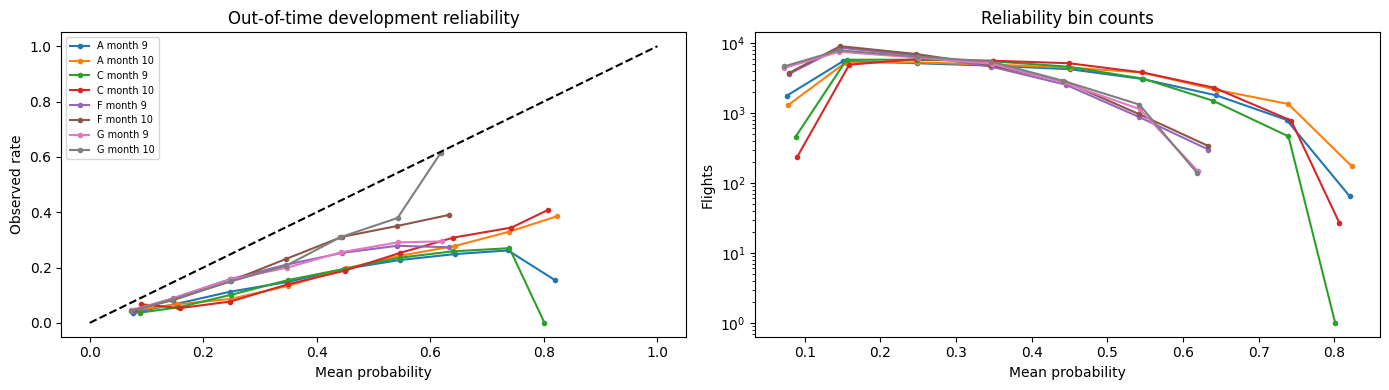

,bin,n,mean_probability,observed_rate,fold,candidate,grid,month
484,"(-0.001, 0.1]",1759,0.076111,0.036953,d,A,primary,9
485,"(0.1, 0.2]",5547,0.151253,0.068145,d,A,primary,9
486,"(0.2, 0.3]",5141,0.247905,0.112819,d,A,primary,9
487,"(0.3, 0.4]",4744,0.347756,0.147766,d,A,primary,9
488,"(0.4, 0.5]",4218,0.450726,0.195590,d,A,primary,9
...,...,...,...,...,...,...,...,...
693,"(0.2, 0.3]",6404,0.248409,0.149594,d,G,primary,10
694,"(0.3, 0.4]",5425,0.346487,0.207189,d,G,primary,10
695,"(0.4, 0.5]",2880,0.441647,0.309722,d,G,primary,10
696,"(0.5, 0.6]",1319,0.542250,0.379075,d,G,primary,10


In [5]:
g=monthly.loc[monthly.fold.eq('d')&monthly.grid.eq('primary')]
display(g[['candidate','month','n','positive_count','prevalence','mean_probability','precision','recall','f1','roc_auc','average_precision','tpr','fpr','f1_q20','brier','log_loss']])
bins=pd.read_csv(OUT/'fold_reliability.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4))
for name in 'ACFG':
    for month in [9,10]:
        b=bins.loc[bins.fold.eq('d')&bins.grid.eq('primary')&bins.candidate.eq(name)&bins.month.eq(month)]
        axes[0].plot(b.mean_probability,b.observed_rate,marker='.',label=f'{name} month {month}')
        axes[1].plot(b.mean_probability,b.n,marker='.',label=f'{name} month {month}')
axes[0].plot([0,1],[0,1],'k--');axes[0].set(title='Out-of-time development reliability',xlabel='Mean probability',ylabel='Observed rate')
axes[1].set(title='Reliability bin counts',xlabel='Mean probability',ylabel='Flights',yscale='log')
axes[0].legend(fontsize=7);plt.tight_layout();plt.show()
display(bins.loc[bins.fold.eq('d')&bins.grid.eq('primary')&bins.candidate.isin(list('ACFG'))])

## Paired day and seven-day block uncertainty
500 fixed-seed replicates retain fitted predictions/thresholds. Intervals do not correct prior selection, reused data, overlapping folds or all seasonality. Do not infer significance merely from flight count.

,candidate,reference,metric,point_difference,ci_low,ci_high,scheme,replicates,seed,valid_replicates
0,C,A,f1,0.006589,0.004356,0.010242,moving_7_day,500,42,500
1,C,A,roc_auc,0.006087,0.003101,0.010130,moving_7_day,500,42,500
2,C,A,average_precision,0.005395,0.003281,0.008944,moving_7_day,500,42,500
3,F,A,f1,0.015310,0.009076,0.020213,moving_7_day,500,42,500
4,F,A,roc_auc,0.014610,0.006699,0.016965,moving_7_day,500,42,500
5,F,A,average_precision,0.014326,0.003889,0.020120,moving_7_day,500,42,500
6,G,A,f1,0.019883,0.012289,0.026115,moving_7_day,500,42,500
7,G,A,roc_auc,0.021131,0.013595,0.023650,moving_7_day,500,42,500
8,G,A,average_precision,0.027654,0.013216,0.038057,moving_7_day,500,42,500
9,F,C,f1,0.008721,0.003473,0.011346,moving_7_day,500,42,500


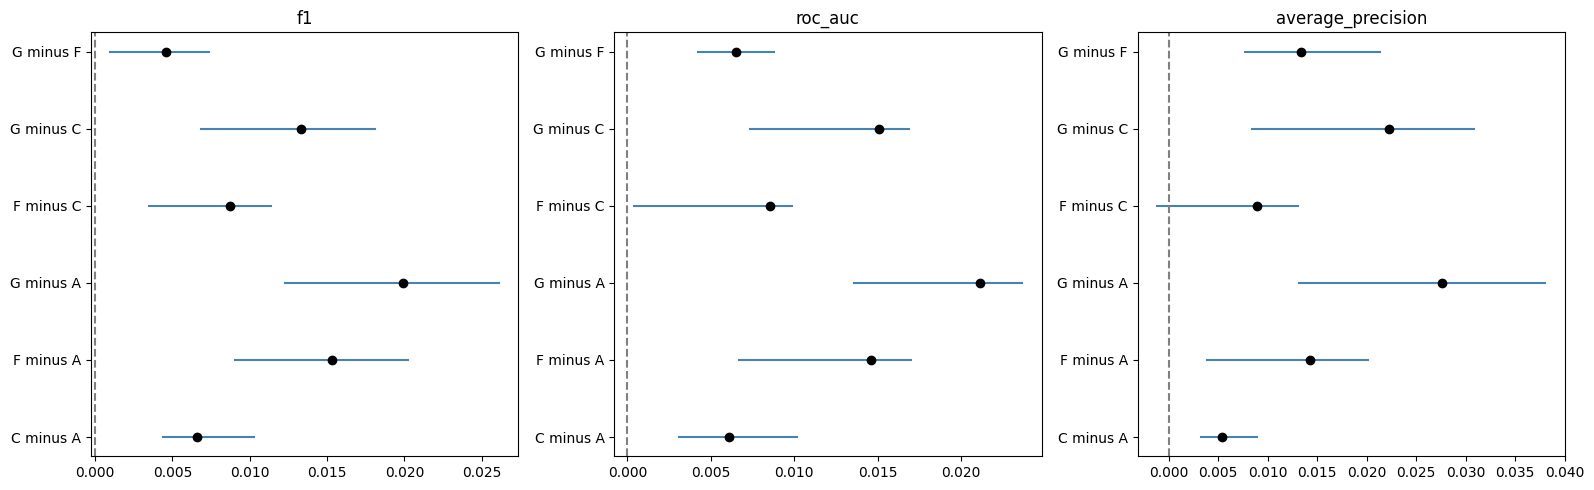

,candidate,reference,metric,point_difference,ci_low,ci_high,scheme,replicates,seed,valid_replicates
0,decision_tree,logistic_regression,f1,-0.014051,-0.028149,-0.002825,whole_day,500,42,500
3,random_forest,logistic_regression,f1,-0.002757,-0.009499,0.004221,whole_day,500,42,500
6,lr_cyclic_C1,logistic_regression,f1,0.005423,-0.001529,0.012554,whole_day,500,42,500
9,forest_interactions_d14,logistic_regression,f1,0.001094,-0.004988,0.006730,whole_day,500,42,500


,fold,candidate,iterations,encoded_dimension,convergence_warnings
0,a,A,[16],2479,0
1,a,B,[16],2477,0
2,a,C,[7],122,0
3,a,D,[16],2485,0
4,a,E,[18],2482,0
5,a,F,[7],126,0
6,a,G,100,8,0
7,b,A,[16],2703,0
8,b,B,[19],2701,0
9,b,C,[7],123,0


In [6]:
intervals=pd.read_csv(OUT/'fold_d_block_bootstrap.csv')
display(intervals)
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,metric in zip(axes,['f1','roc_auc','average_precision']):
    g=intervals.loc[intervals.metric.eq(metric)].reset_index(drop=True)
    labels=g.candidate+' minus '+g.reference
    for i,row in g.iterrows():
        ax.plot([row.ci_low,row.ci_high],[i,i],color='steelblue')
        ax.plot(row.point_difference,i,'ko')
    ax.axvline(0,color='gray',linestyle='--');ax.set(yticks=range(len(g)),yticklabels=labels,title=metric)
plt.tight_layout();plt.show()
display(pd.read_csv(OUT/'historical_day_bootstrap.csv').query("metric == 'f1'"))
display(pd.DataFrame(json.loads((OUT/'convergence.json').read_text()))[['fold','candidate','iterations','encoded_dimension','convergence_warnings']])

## Review boundary
No production model, previous report, source dataset, prior study or selection file is replaced. This notebook performs no next-stage work. Review the independent report and paired differences before deciding whether any simplification merits integration.